In [1]:
import numpy as np
import astropy
from astropy.io import fits
import sep
import matplotlib.pyplot as plt
from matplotlib import rcParams

The edit to `rcParams` here will affect the default `figsize` for all subsequent `Figures` created without explicitly set `figsize` values.  
Additionally, the `%matplotlib inline` jupyter "magic" is used to ensure that all figures are show in the notebook itself and not with some external, interactive backend

In [2]:
%matplotlib inline 
rcParams['figure.figsize'] = [10.,8.]

Using the `astropy.io.fits.getdata` function to open up the file and pull the data directly and without having to handle an hdu list object.

In [3]:
data = fits.getdata('./image.fits',)

ESO-LOG 00:00:00> DATE         = '1992-10-26'  / Mon Oct 26, 1992                [astropy.io.fits.card]
ESO-LOG 03:04:08>-START EXPO EMMI RED          / Start exp. on EMMI Red CC       [astropy.io.fits.card]
ESO-LOG 03:04:09> EXPO EMMI RED NO = 24887     / Exp. num. on EMMI Red CCD       [astropy.io.fits.card]
ESO-LOG 03:10:52>-STOP EXPO EMMI RED           / Stop exp. on EMMI Red CCD       [astropy.io.fits.card]


The image data is shown in grey scale using `matplotlib`.  
The mean and standard deviations are used to clamp the image data to within one sigma of the mean, while nearest neighbor interpolation is used to fill in any gaps. Additionally a `colorbar` is rendered to facilitate interpretation of the data. 

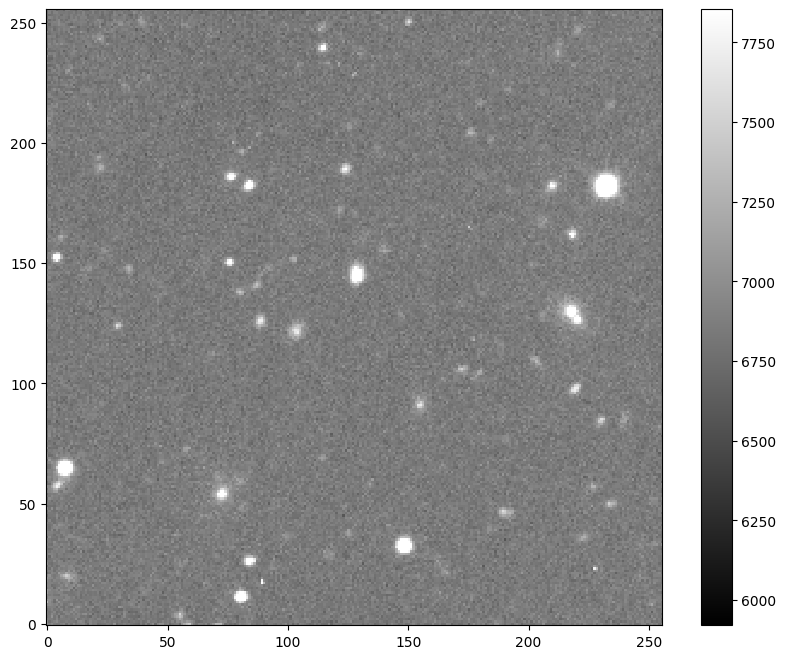

In [4]:
m, s = np.mean(data), np.std(data)
plt.imshow(data, interpolation='nearest',cmap='grey',vmin=m-s,vmax=m+s,origin='lower')
_ = plt.colorbar()
plt.savefig('tutorial_1_raw.png',bbox_inches='tight',dpi = 600)

The background ans noise of the characteristics of the data are calculated by `sep` using an instance of the `Background` object.

In [5]:
bkg = sep.Background(data)

The `Background` object calculates both the mean background value and a noise value for the image.

In [6]:
# get a "global" mean and noise of the image background:
print(bkg.globalback)
print(bkg.globalrms)

6852.04931640625
65.46174621582031


Demonstrates how to get a `numpy` array version of the data stored in the `Background` object.

In [7]:
bkg_image = bkg.back()

Uses the array form of the background data to plot an image using `matplotlib`.

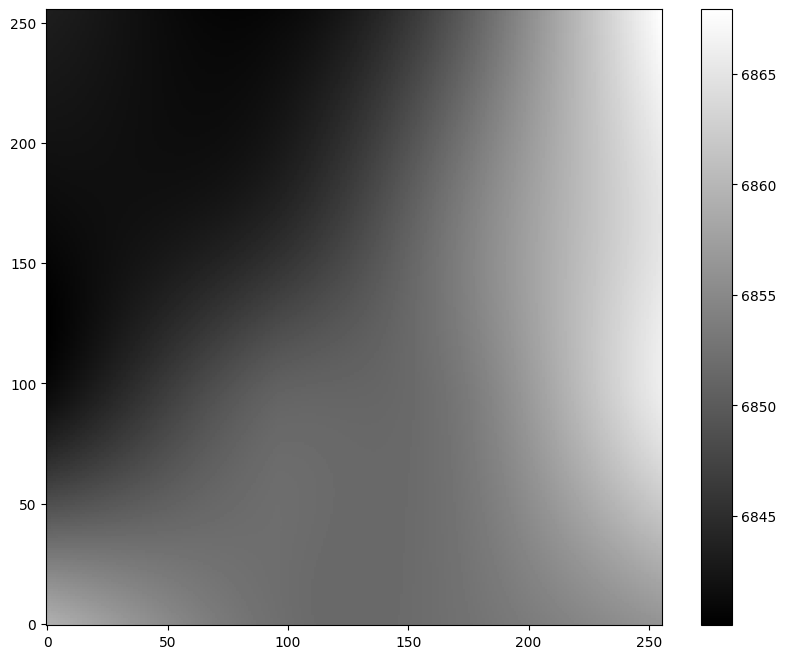

In [8]:
# show the background
plt.imshow(bkg_image, interpolation='nearest', cmap='gray', origin='lower')
_ = plt.colorbar()
plt.savefig('tutorial_2_background.png',bbox_inches='tight',dpi = 600)

Shows how to get the noise data stored in the `Background` object as a `numpy` array.

In [9]:
# evaluate the background noise as 2-d array, same size as original image
bkg_rms = bkg.rms()

Plots the noise data in the same fashion as the background data.

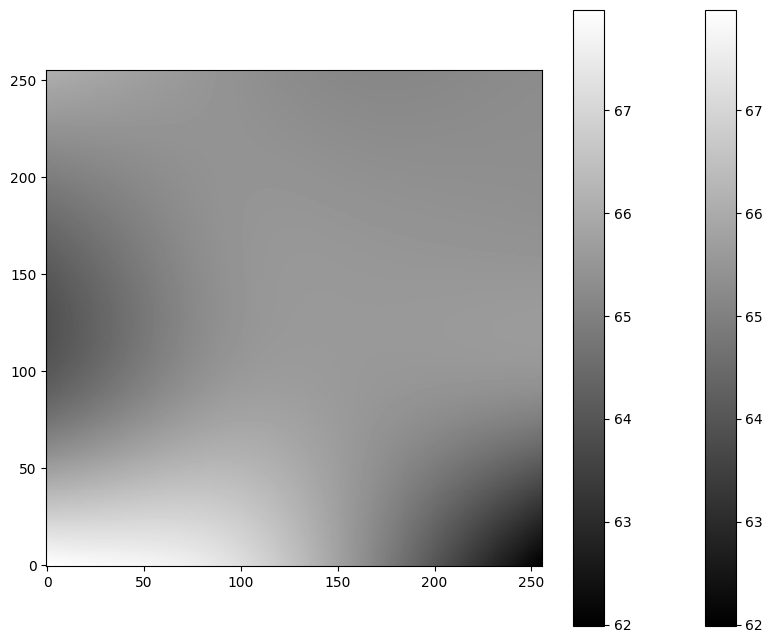

In [10]:
# show the background noise
plt.imshow(bkg_rms, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar()
_ = plt.colorbar()
plt.savefig('tutorial_3_noise.png',bbox_inches='tight',dpi = 600)

Subtracts the background data and noise from the origin image data. This facilitates the image extraction and avoids    accidentally extracting patches of noise as though they were objects. 

In [11]:
data_sub = data - bkg

Uses the background-subtracted image data in a call to `sep`'s `extract` function. The threshold is set at 1.5*sigma and will be dynamically adjust on a per-pixel basis with the noise values stored in `bkg.globalrms`. The object data is stored in a structered `numpy` array.

In [12]:
objects = sep.extract(data_sub, 1.5, err=bkg.globalrms)

Gets a quick count of how many objects were detected.

In [13]:
len(objects)

69

Plots the background-subtracted image data in the same way as the raw data, then iterates through each object and uses the stored values for:
 - the x and y position,
 - the orthogonal major and minor axes of the object's enclosing ellipse,
 - and the angle to which those axes are rotated from the standard i,j basis
to plot ellipses on the image where the detected object lie. 

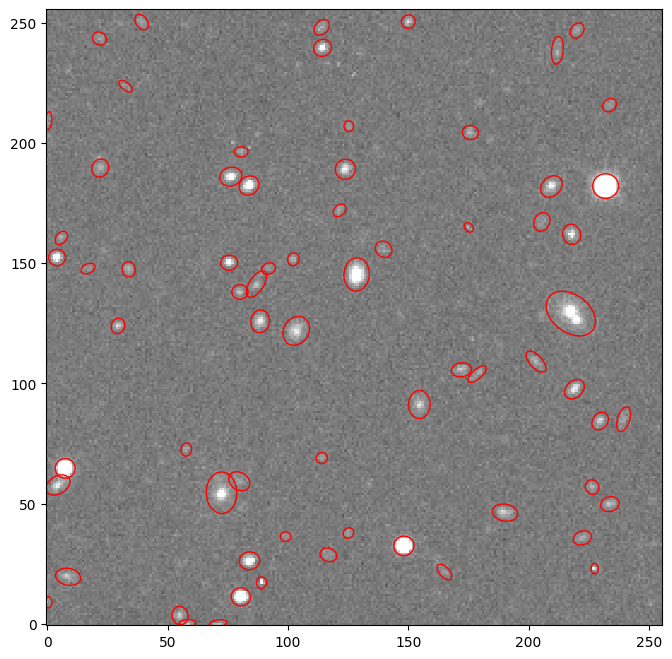

In [14]:
from matplotlib.patches import Ellipse

# plot background-subtracted image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray',
               vmin=m-s, vmax=m+s, origin='lower')

# plot an ellipse for each object
for i in range(len(objects)):
    e = Ellipse(xy=(objects['x'][i], objects['y'][i]),
                width=6*objects['a'][i],
                height=6*objects['b'][i],
                angle=objects['theta'][i] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

plt.savefig('tutorial_4_detection.png',bbox_inches='tight',dpi = 600)

Demonstrates how to access the available fields of the structured array return by `sep.extract`.

In [15]:
objects.dtype.names

('thresh',
 'npix',
 'tnpix',
 'xmin',
 'xmax',
 'ymin',
 'ymax',
 'x',
 'y',
 'x2',
 'y2',
 'xy',
 'errx2',
 'erry2',
 'errxy',
 'a',
 'b',
 'theta',
 'cxx',
 'cyy',
 'cxy',
 'cflux',
 'flux',
 'cpeak',
 'peak',
 'xcpeak',
 'ycpeak',
 'xpeak',
 'ypeak',
 'flag')

Computes the brightness of each of the detected objects using simple circular photometry. Instead of defining an outer annulus to get the background/noise value to subtract, uses the background object's global value. 

In [16]:
flux, fluxerr, flag = sep.sum_circle(data_sub, objects['x'], objects['y'],
                                     3.0, err=bkg.globalrms, gain=1.0)

Show the calculated flux and error for the first ten objects.

In [17]:
for i in range(10):
    print("object {:d}: flux = {:f} +/- {:f}".format(i, flux[i], fluxerr[i]))

object 0: flux = 2249.159297 +/- 291.027802
object 1: flux = 3092.220430 +/- 291.592204
object 2: flux = 5949.868379 +/- 356.562003
object 3: flux = 1851.426582 +/- 295.028816
object 4: flux = 72736.386914 +/- 440.172206
object 5: flux = 3860.756152 +/- 352.163162
object 6: flux = 6418.913789 +/- 357.458973
object 7: flux = 2210.707656 +/- 350.791223
object 8: flux = 2741.607227 +/- 352.277746
object 9: flux = 20916.875566 +/- 376.966138
